In [1]:
import json
import sys
from pathlib import Path

HICOLA_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'scripts' / 'hicola_paths.py').exists())
sys.path.insert(0, str(HICOLA_ROOT / 'scripts'))
import hicola_paths as hp
sys.path.insert(0, str(hp.HODDIES_ROOT))
for module_name in list(sys.modules):
    if module_name == 'HODDIES' or module_name.startswith('HODDIES.'):
        del sys.modules[module_name]

import numpy as np
import matplotlib.pyplot as plt
from HODDIES import HOD
from euclid_reference_cosmology import SERIALIZABLE_PARAMETERS, PARAMETERS
import HODDIES

print(f'Using HODDIES from {HODDIES.__file__}')


Using HODDIES from /home/biel/HODDIES/HODDIES/__init__.py


In [45]:
from cosmoprimo.fiducial import Cosmology

euclid_cosmo = Cosmology(
    Omega0_m=SERIALIZABLE_PARAMETERS['Omega_m'],
    Omega_b=SERIALIZABLE_PARAMETERS['Omega_b'],
    h=SERIALIZABLE_PARAMETERS['h'],
    sigma8=SERIALIZABLE_PARAMETERS['sigma8'],
    n_s=SERIALIZABLE_PARAMETERS['n_s'],
    w0_fld=SERIALIZABLE_PARAMETERS['w0'],
    wa_fld=SERIALIZABLE_PARAMETERS['wa'],
    T_cmb=SERIALIZABLE_PARAMETERS['Tcmb0_K'],
    N_eff=SERIALIZABLE_PARAMETERS['Neff'],
    m_ncdm=[],
    engine='class',
)

print(SERIALIZABLE_PARAMETERS)
euclid_cosmo.get_params()


{'H0_km_s_Mpc': 67.0, 'h': 0.67, 'Omega_m': 0.319, 'Omega_cdm': 0.27, 'Omega_b': 0.049, 'Omega_Lambda': 0.681, 'Tcmb0_K': 2.726, 'Neff': 3.046, 'n_s': 0.96, 'A_s': 2.10521e-09, 'sigma8': 0.816, 'w0': -1.0, 'wa': 0.0}


{'Omega_k': 0.0,
 'k_pivot': 0.05,
 'alpha_s': 0.0,
 'beta_s': 0.0,
 'r': 0.0,
 'n_t': -0.0,
 'alpha_t': -0.0,
 'T_ncdm_over_cmb': array([], dtype=float64),
 'tau_reio': 0.06,
 'reionization_width': 0.5,
 'A_L': 1.0,
 'cs2_fld': array(1.),
 'non_linear': '',
 'modes': ['s'],
 'lensing': False,
 'z_pk': array([ 0.        ,  0.01189061,  0.04756243,  0.10701546,  0.1902497 ,
         0.29726516,  0.42806183,  0.58263971,  0.76099881,  0.96313912,
         1.18906064,  1.43876338,  1.71224732,  2.00951249,  2.33055886,
         2.67538644,  3.04399524,  3.43638526,  3.85255648,  4.29250892,
         4.75624257,  5.24375743,  5.75505351,  6.2901308 ,  6.8489893 ,
         7.43162901,  8.03804994,  8.66825208,  9.32223543, 10.        ]),
 'kmax_pk': 10.0,
 'ellmax_cl': 2500,
 'YHe': 'BBN',
 'use_ppf': True,
 'Omega_b': array(0.049),
 'h': array(0.67),
 'sigma8': array(0.816),
 'n_s': 0.96,
 'w0_fld': array(-1.),
 'wa_fld': array(0.),
 'T_cmb': array(2.726),
 'N_ur': array(3.046),
 'm_ncdm':

In [46]:
target, model, realization = 'COLA_NM4096', 'LCDM', 's1234'
boxsize = hp.TARGETS[target]['boxsize']
redshift = 1.650

OUTPUT_DIR = hp.halo_catalog_dir(target, model, realization, redshift)
HALO_CATALOG = OUTPUT_DIR / 'halos200c_catalog.npy'
HALO_METADATA = Path(str(HALO_CATALOG) + '.json')
HODDIES_CATALOG = OUTPUT_DIR / 'halos200c_hoddies.npy'
HMF_OUTPUT = OUTPUT_DIR / 'halos200c_hmf.txt'
ANALYSIS_DIR = OUTPUT_DIR / 'analysis'
PARAM_FILE = str(hp.NOTEBOOK_DIR / f'HOD_parameter_file_z{redshift:.3f}.yaml')

print(f'Halo catalog: {HALO_CATALOG}')
print(f'HODDIES catalog: {HODDIES_CATALOG}')
print(f'HMF output: {HMF_OUTPUT}')
print(f'Analysis directory: {ANALYSIS_DIR}')


Halo catalog: /scratch/biel/LCDM_Bart/snapshot_LCDM_Bart_z1.650/halo_catalog/halos200c_catalog.npy
HODDIES catalog: /scratch/biel/LCDM_Bart/snapshot_LCDM_Bart_z1.650/halo_catalog/halos200c_hoddies.npy
HMF output: /scratch/biel/LCDM_Bart/snapshot_LCDM_Bart_z1.650/halo_catalog/halos200c_hmf.txt
Analysis directory: /scratch/biel/LCDM_Bart/snapshot_LCDM_Bart_z1.650/halo_catalog/analysis


In [47]:
if not HODDIES_CATALOG.exists():
    raise FileNotFoundError(
        f'Missing {HODDIES_CATALOG}. Run jobs/submit_halo_finder.sh on this run first, '
        'then come back to this notebook.'
    )

arr = np.load(HODDIES_CATALOG)
print(f'Loaded {len(arr):,} HODDIES-ready halos')
print(arr.dtype)

if HALO_METADATA.exists():
    with HALO_METADATA.open() as f:
        halo_metadata = json.load(f)
    print(json.dumps(halo_metadata, indent=2))
else:
    halo_metadata = {}

expected_cosmology = SERIALIZABLE_PARAMETERS
halo_cosmology = halo_metadata.get('cosmology')
if halo_cosmology is not None:
    mismatches = {
        key: (halo_cosmology.get(key), expected)
        for key, expected in expected_cosmology.items()
        if key in halo_cosmology and not np.isclose(float(halo_cosmology[key]), float(expected))
    }
    if mismatches:
        raise ValueError(f'Halo catalog cosmology metadata does not match Euclid reference: {mismatches}')
else:
    print('Halo catalog metadata has no cosmology block; using notebook Euclid reference cosmology.')


Loaded 799,331 HODDIES-ready halos
[('x', '<f8'), ('y', '<f8'), ('z', '<f8'), ('vx', '<f8'), ('vy', '<f8'), ('vz', '<f8'), ('Mh', '<f8'), ('log10_Mh', '<f8'), ('Rh', '<f8'), ('Rs', '<f8'), ('c', '<f8'), ('Vrms', '<f8'), ('halo_id', '<i8')]
{
  "boxsize": 1024.0,
  "cosmology": {
    "A_s": 2.10521e-09,
    "H0_km_s_Mpc": 67.0,
    "Neff": 3.046,
    "Omega_Lambda": 0.681,
    "Omega_b": 0.049,
    "Omega_cdm": 0.27,
    "Omega_m": 0.319,
    "Tcmb0_K": 2.726,
    "h": 0.67,
    "n_s": 0.96,
    "sigma8": 0.816,
    "w0": -1.0,
    "wa": 0.0
  },
  "cosmology_source": "Euclid preparation: VII, arXiv:1910.09273",
  "fields": [
    "x",
    "y",
    "z",
    "vx",
    "vy",
    "vz",
    "m200c",
    "log10_m200c",
    "r200c",
    "rs",
    "c",
    "vrms",
    "length",
    "halo_id"
  ],
  "halos": 799331,
  "linking_length": 0.2,
  "mass_field": "m200c",
  "mass_units": "Msun/h",
  "mdef": "200c",
  "mpi_ranks": 512,
  "nmin": 30,
  "output": "/scratch/biel/LCDM_Bart/snapshot_LCDM_Bar

In [48]:
print('Mass range:', arr['Mh'].min(), arr['Mh'].max())
print('log10_Mh range:', arr['log10_Mh'].min(), arr['log10_Mh'].max())
print('Position mins:', np.min(np.vstack([arr['x'], arr['y'], arr['z']]).T, axis=0))
print('Position maxs:', np.max(np.vstack([arr['x'], arr['y'], arr['z']]).T, axis=0))


Mass range: 2744549593430.716 466307829309663.8
log10_Mh range: 12.438471082797976 14.668672707321186
Position mins: [6.72764145e-05 3.87115404e-04 2.75525963e-04]
Position maxs: [1023.9987793  1023.99951172 1023.99914551]


In [49]:
HOD_obj = HOD(hcat_file=arr, **{'hcat': {'boxsize': boxsize}}, param_file=PARAM_FILE)
HOD_obj.args['hcat']['z_simu'] = redshift
HOD_obj.args['cosmo'].update({
    'fiducial_cosmo': None,
    'engine': 'class',
    'h': SERIALIZABLE_PARAMETERS['h'],
    'Omega_m': SERIALIZABLE_PARAMETERS['Omega_m'],
    'Omega_cdm': SERIALIZABLE_PARAMETERS['Omega_cdm'],
    'Omega_L': SERIALIZABLE_PARAMETERS['Omega_Lambda'],
    'Omega_b': SERIALIZABLE_PARAMETERS['Omega_b'],
    'sigma_8': SERIALIZABLE_PARAMETERS['sigma8'],
    'n_s': SERIALIZABLE_PARAMETERS['n_s'],
    'w0_fdl': SERIALIZABLE_PARAMETERS['w0'],
    'wa_fdl': SERIALIZABLE_PARAMETERS['wa'],
})
HOD_obj.cosmo = euclid_cosmo


Set number of threads to 32
Initialize custom cosmology from the "cosmo" parameters


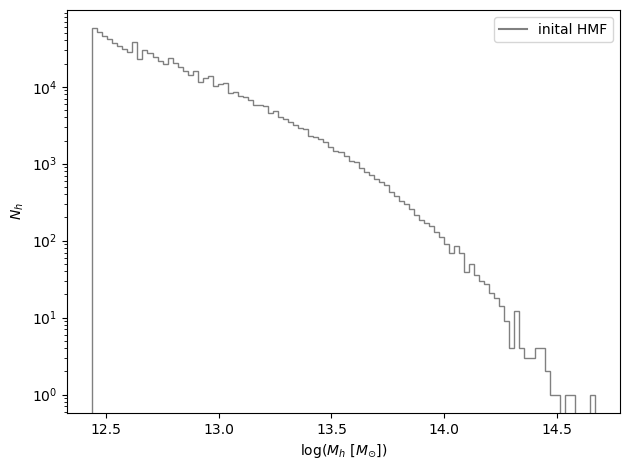

In [50]:
HOD_obj.plot_initial_HMF()

In [51]:
cat = HOD_obj.make_mock_cat(tracers='LRG', fix_seed=42)

Create mock catalog for ['LRG']
Run HOD for LRG
Set density to 0.0007 gal/Mpc/h


/home/biel/HODDIES/HODDIES/hod.py:884: UserWarning: Ac=1.7186709494375827 is > 1, the density is not fixed to 0.0007
  warnings.warn('Ac={} is > 1, the density is not fixed to {}'.format(hod_list_param_cen[0]*ds, self.args[tracer]["density"]))


HOD Computed 1.4737279415130615
Start satellite assignement
Satellite assignement done 1.0582275390625
LRG mock catalogue done 1.062434434890747
17960 central galaxies, 92 satellites, fraction of satellite 0.01 
Done overall time  LRG 2.54290771484375


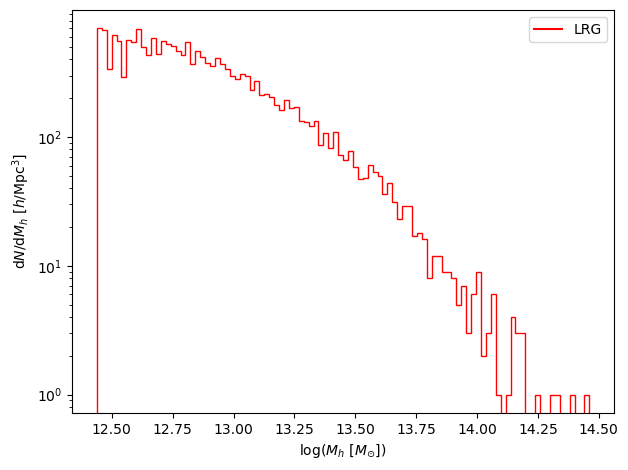

In [52]:
HOD_obj.plot_HMF(cat,tracer='LRG')

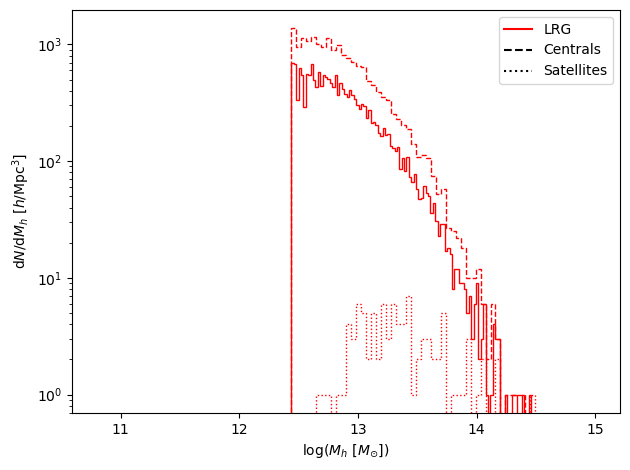

In [53]:
HOD_obj.plot_HMF(cat, show_sat=True, tracer='LRG')

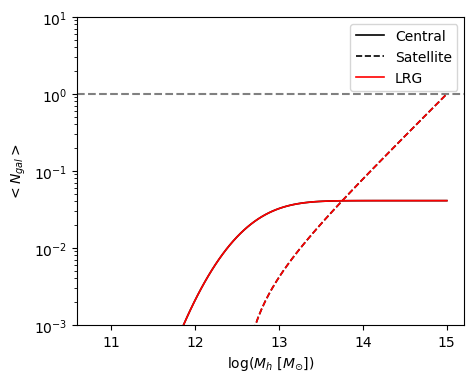

In [54]:
HOD_obj.HOD_plot()

In [55]:
rp, wp = HOD_obj.get_wp(cat, tracers='LRG')
s, xi = HOD_obj.get_2PCF(cat, tracers='LRG')

#Compute wp for LRG...
Done in 1.087 s
#Compute xi(s,mu) using l=[0, 2] for LRG...
#Done in 1.000 s


In [56]:
HOD_obj.args['LRG']['link_sat_to_central'] = True

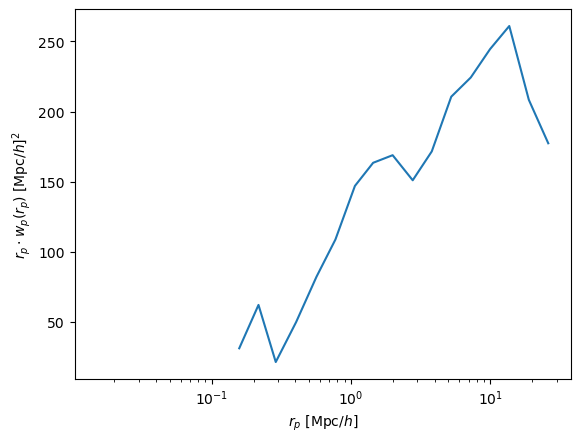

In [57]:
plt.plot(rp,rp*wp)
plt.xscale('log')
plt.xlabel('$r_p$ [$\mathrm{{Mpc}}/h$]')
plt.ylabel(r'$r_p \cdot w_p(r_p)$ [$\mathrm{{Mpc}}/h$]$^2$')
plt.show()

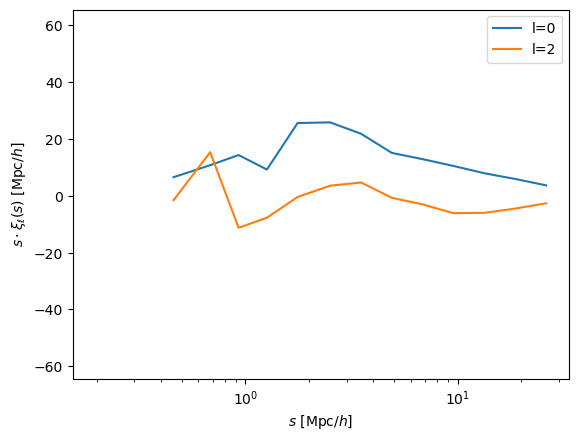

In [58]:
plt.plot(s,s*xi[0], label='l=0')
plt.plot(s,s*xi[1], label='l=2')
plt.xscale('log')
plt.xlabel('$s$ [$\mathrm{{Mpc}}/h$]')
plt.ylabel(r'$s \cdot \xi_{\ell}(s)$ [$\mathrm{{Mpc}}/h$]')
plt.legend()
plt.show()